# Exercise 3.1: Black-Scholes solution
> **Goal**: compute $C[S(0), 0]$ (the *call-option price*) and $P[S(0), 0]$ (the *put-option price*) describing the asset price at time $t=0$ in Black-Scholes theory
> $$\begin{align*}
> C\left[ S(t),t \right] &= S(t) N(d_1) -K e^{-r(T-t)} N(d_2) \\
> P\left[ S(t),t \right] &= S(t) \left[ N(d_1)-1\right] -K e^{-r(T-t)} \left[ N(d_2)-1\right]
> \end{align*}$$ 
> where
> $$\begin{align*}
> d_1 &= \frac{1}{\sigma\sqrt{T-t}}\left[ \ln \left( \frac{S(t)}{K} \right) + \left( r+\frac{\sigma^2}{2} (T-t) \right)\right] \\
> d_2 &= d_1 - \sigma\sqrt{T-t} \\
> N(x) &= \int_{-\infty}^{x} dz \, e^{-\frac{z^2}{2}} = \frac{1}{2} \left[ 1+ {\rm erf} \left( \frac{x}{\sqrt{2}}\right) \right] \\
> {\rm erf}(x) &= \frac{2}{\sqrt{\pi}}\int_{0}^{x} dz \, e^{-z^2}
> \end{align*}$$
> 
> *note*: $N(x)$ is the cumulative function of Gaussian $\sim \mathcal{N}(\mu=0,\sigma^2=1)$.
>
> Assume the following:
>   - $S(0) = 100$ *asset price at $t=0$*
>   - $T = 1$ *delivery time*
>   - $K = 100$ *strike price*
>   - $r = 0.1$ *risk-free interest rate*
>   - $\sigma = 0.25$ *volatility*
> 
> and perform the computation
>   1. sampling directly $S(T)$ for a $GBM(r, \sigma^2)$
>   2. sampling the discretized $GBM(r,\sigma^2)$ path of the asset price, dividing $[0,T]$ in $10^2$ time intervals: $S(0)$, $S(t_1)$, $S(t_2)$, ... up to $S(t_{100}=T=1)$
>
> *note*: given an asset price $S\sim GBM(r,\sigma^2)$, with initial value $S(0)$, then
> $$S(t) = S(0) \exp\left[ \left(r-\frac{1}{2}\sigma^2\right)t+\sigma W(t)\right]$$
> where $W(t)\sim\mathcal{N}(0,t)$.
> Moreover, since the increments of $W$ are independent and normally distributed, the simple recursive procedure for sampling discretized values of $S\sim GBM(r,\sigma^2)$ > at $t_1 < t_2 < … < t_n$ is:
> $$S(t_{i+1}) = S(t_i) \exp\left[ \left(r-\frac{1}{2}\sigma^2\right)(t_{i+1}-t_i) + \sigma Z_{i+1}\sqrt{t_{i+1}-t_i}\right]$$
> with $Z_i \sim \mathcal{N}(0,1)$
> Lastly, plot both values, each in both metods, as progressive functions of the number of blocks $N$, each block with a large number of asset prices at $t=T$ (*e.g. $M=1e4$*), and compare the results

At $t = 0$
$$\begin{align}
  C\left[ S(0),0 \right] &= S(0) N(d_1\big|_{t=0}) -K e^{-rT} N(d_2\big|_{t=0}) \\
  P\left[ S(0),0 \right] &= S(0) \left[ N(d_1\big|_{t=0})-1\right] -K e^{-rT} \left[ N(d_2\big|_{t=0})-1\right] \\
  \text{where}\quad d_1\big|_{t=0} &= \frac{1}{\sigma\sqrt{T}}\left[ \ln \left( \frac{S(0)}{K} \right) + \left( r+\frac{\sigma^2}{2} T \right)\right]
\end{align}$$

First we generate Brownian motion data, using the `wiener` function:
  - `brownian_motion_direct` is an array of values for $\mathcal{W}(T)$ directly sampled from $\mathcal{N}(0,T)$
  - `brownian motion series` is an array of time series $\mathcal{W}(t_i)$, generated as a Wiener process whose increments are sampled from $\mathcal{N}(0, dt)$
  
From these we obtain samples for the asset price
  - `S_T_direct`: an array of single-valued samples $S(T) = S(0)\exp\big\{(r-\frac{1}{2}\sigma^2)T + \sigma\mathcal{W}(T)\sqrt{T}\big\}$
  - `S_series`: an array of time series $S(t_i) = S(t_{i-1})\exp\big\{(r-\frac{1}{2}\sigma^2)dt + \sigma\mathcal{W}(t_i)\sqrt{dt}\big\}$

Lastly, we get data on the option prices using
$$
C(t) = e^{-r(T-t)}\max\big(S(t) - K, 0\big) \quad\text{and}\quad P(t) = e^{-r(T-t)}\max\big(K - S(t), 0\big)
$$
  - `C_samples` and `P_samples` are arrays of single-valued evaluation for curent prices $C(t=0)$ and $P(t=0)$ based only on $S(T)$
  - `C_samples_series` and `P_samples_series` are arrays of time-series $C(t_i)$ and $P(t_i)$, each describing a prediction for option prices trends based on a $S(t_i)$

In [18]:
import numpy as np
import subprocess
import matplotlib.pyplot as plt

def wiener(N_reps, dt, N_steps):
  output = subprocess.run(["./run", str(N_reps), "wiener", str(dt), str(N_steps)],
                          cwd="./rannyu_rng",
                          capture_output=True,
                          text=True)
  return np.array([ list(map(float, line.split())) for line in output.stdout.strip().split('\n') ])

N_blocks = 100
N_samples_per_block = int(1e3)
N_sample_times = int(1e2)

S_0 = 100.
K = 100.
T = 1.
r = 0.1
sigma = 0.25
dt = T / N_sample_times

brownian_motion_direct = wiener(N_blocks * N_samples_per_block, T, 1)[:,1]
S_T_direct = S_0 * np.exp( (r - 0.5 * sigma**2) * T + sigma * brownian_motion_direct * np.sqrt(T) )
C_samples_direct = np.exp(-r * T) * np.maximum(S_T_direct - K, 0)
P_samples_direct = np.exp(-r * T) * np.maximum(K - S_T_direct, 0)

brownian_motion_series = wiener(N_blocks * N_samples_per_block, dt, N_sample_times)
S_series = np.array([np.zeros(N_sample_times+1) for i in range(N_blocks * N_samples_per_block)])
S_series[:, 0] = np.array([S_0 for i in range (N_blocks * N_samples_per_block)])
for step in np.arange(1, N_sample_times+1):
  S_series[:, step] = S_series[:, step - 1] * np.exp( (r - 0.5 * sigma**2) * dt + sigma * (brownian_motion_series[:, step] - brownian_motion_series[:, step - 1]) )
C_samples_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks * N_samples_per_block)])
P_samples_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks * N_samples_per_block)])
for step in range(N_sample_times + 1):
  C_samples_series[:, step] = np.exp(-r * (T - step * dt)) * np.maximum(S_series[:, N_sample_times] - K, 0)
  P_samples_series[:, step] = np.exp(-r * (T - step * dt)) * np.maximum(K - S_series[:, N_sample_times], 0)

We then apply data blocking and obtain a progressive (*vs. block number*) estimate for the direct computation:

In [25]:
def error(av, av2, n):
  return np.sqrt((av2 - av*av)/max(1,n-1))

C_blocks_direct = np.zeros(N_blocks)
C_progr_block_av_direct = np.zeros(N_blocks)
C_progr_block_av2_direct = np.zeros(N_blocks)
C_progr_error_direct = np.zeros(N_blocks)
P_blocks_direct = np.zeros(N_blocks)
P_progr_block_av_direct = np.zeros(N_blocks)
P_progr_block_av2_direct = np.zeros(N_blocks)
P_progr_error_direct = np.zeros(N_blocks)

for block in range(N_blocks):
  for i in range(N_samples_per_block):
    C_blocks_direct[block] += C_samples_direct[block * N_samples_per_block + i]
    P_blocks_direct[block] += P_samples_direct[block * N_samples_per_block + i]
  C_blocks_direct[block] /= N_samples_per_block
  P_blocks_direct[block] /= N_samples_per_block

  x = C_blocks_direct[block]
  x = P_blocks_direct[block]
  for i in range(N_blocks - block):
    x =  C_blocks_direct[block]
    C_progr_block_av_direct[block + i] += x
    C_progr_block_av2_direct[block + i] += x * x
    y =  P_blocks_direct[block]
    P_progr_block_av_direct[block + i] += y
    P_progr_block_av2_direct[block + i] += y * y
  C_progr_block_av_direct[block] /= block + 1
  C_progr_block_av2_direct[block] /= block + 1
  P_progr_block_av_direct[block] /= block + 1
  P_progr_block_av2_direct[block] /= block + 1

  av_c = C_progr_block_av_direct[block]
  av2_c = C_progr_block_av2_direct[block]
  C_progr_error_direct[block] = np.sqrt((av2_c - av_c * av_c) / max(1.0, block))
  av_p = P_progr_block_av_direct[block]
  av2_p = P_progr_block_av2_direct[block]
  P_progr_error_direct[block] = np.sqrt((av2_p - av_p * av_p) / max(1.0, block))


print("=== Direct computation results: ===")
print(f"Call-option price: {C_progr_block_av_direct[N_blocks - 1]:.3f} +- {C_progr_error_direct[N_blocks - 1]:.3f}")
print(f"Put-option price: {P_progr_block_av_direct[N_blocks - 1]:.3f} +- {P_progr_error_direct[N_blocks - 1]:.3f}")

=== Direct computation results: ===
Call-option price: 14.991 +- 0.062
Put-option price: 5.450 +- 0.029


and the derived computation:

In [26]:
C_blocks_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks)])
C_progr_block_av_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks)])
C_progr_block_av2_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks)])
C_progr_error_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks)])
P_blocks_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks)])
P_progr_block_av_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks)])
P_progr_block_av2_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks)])
P_progr_error_series = np.array([np.zeros(N_sample_times + 1) for i in range(N_blocks)])

for block in range(N_blocks):
  for i in range(N_samples_per_block):
    C_blocks_series[block] += C_samples_series[block * N_samples_per_block + i]
    P_blocks_series[block] += P_samples_series[block * N_samples_per_block + i]
C_blocks_series /= N_samples_per_block
P_blocks_series /= N_samples_per_block

for block in range(N_blocks):
  for i in range(N_blocks - block):
    C_progr_block_av_series[block + i] += C_blocks_series[block]
    C_progr_block_av2_series[block + i] += C_blocks_series[block]**2
    P_progr_block_av_series[block + i] += P_blocks_series[block]
    P_progr_block_av2_series[block + i] += P_blocks_series[block]**2
  C_progr_block_av_series[block] /= block + 1
  C_progr_block_av2_series[block] /= block + 1
  P_progr_block_av_series[block] /= block + 1
  P_progr_block_av2_series[block] /= block + 1
  for step in range(N_sample_times + 1):
    C_progr_error_series[block, step] = error(C_progr_block_av_series[block, step], C_progr_block_av2_series[block, step], block + 1)
    P_progr_error_series[block, step] = error(P_progr_block_av_series[block, step], P_progr_block_av2_series[block, step], block + 1)

print("=== Derived computation results: ===")
print(f"Call-option price: {C_progr_block_av_series[N_blocks - 1, 0]:.3f} +- {C_progr_error_series[N_blocks - 1, 0]:.3f}")
print(f"Put-option price: {P_progr_block_av_series[N_blocks - 1, 0]:.3f} +- {P_progr_error_series[N_blocks - 1, 0]:.3f}")

=== Derived computation results: ===
Call-option price: 14.924 +- 0.068
Put-option price: 5.438 +- 0.029


In [27]:
import numpy as np
from scipy.special import erf

def N(x):
    return 0.5 * (1. + erf(x / np.sqrt(2.)))

def black_scholes(S0, K, T, r, sigma):
    d1 = 1./(sigma * np.sqrt(T)) * (np.log(S0 / K) + (r + (sigma**2) / 2.) * T)
    d2 = d1 - sigma * np.sqrt(T)
    C = S0 * N(d1) - K * np.exp(-r * T) * N(d2)
    P = S0 *(N(d1) - 1.) - K * np.exp(-r * T) * (N(d2)-1.)
    return C, P

call, put = black_scholes(S_0, K, T, r, sigma)
print(" == Black-Scholes analytic solution ==")
print(f"call: {call:.3f}")
print(f"put: {put:.3f}")

 == Black-Scholes analytic solution ==
call: 14.976
put: 5.460


We can now plot the results againt the theory:

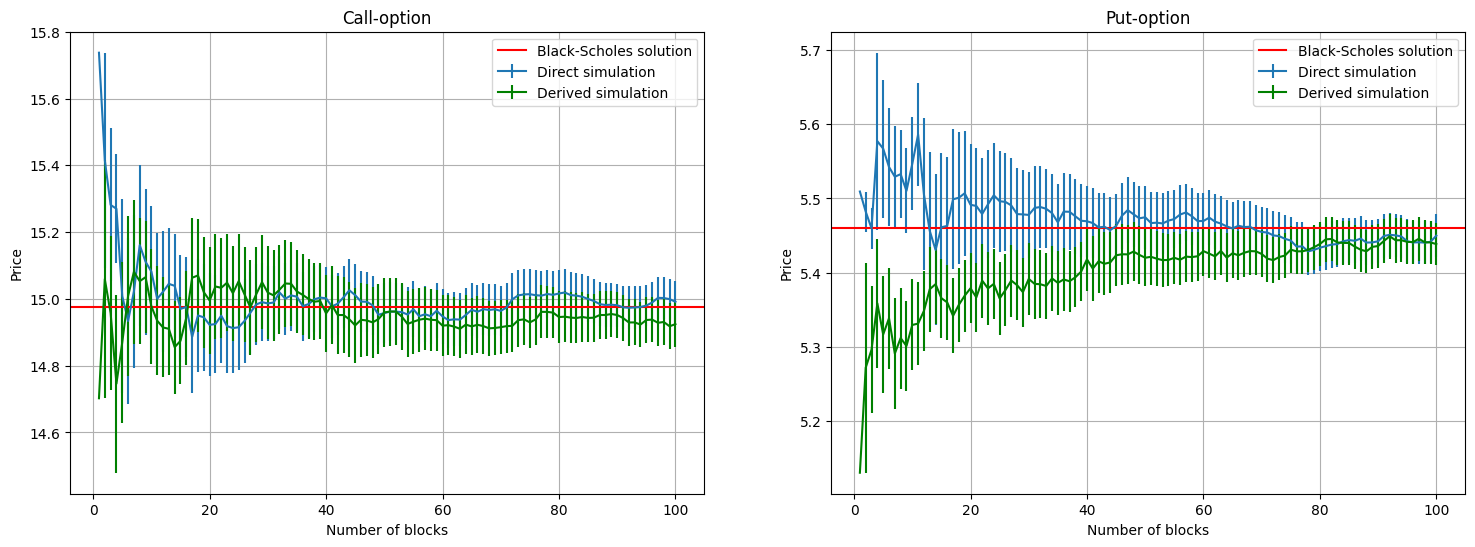

In [28]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2)
fig.set_figwidth(18)
fig.set_figheight(6)

axs[0].errorbar(np.arange(1, N_blocks + 1), C_progr_block_av_direct, yerr=C_progr_error_direct, label="Direct simulation")
axs[1].errorbar(np.arange(1, N_blocks + 1), P_progr_block_av_direct, yerr=P_progr_error_direct, label="Direct simulation")
axs[0].errorbar(np.arange(1, N_blocks + 1), C_progr_block_av_series[:, 0], yerr=C_progr_error_series[:, 0], label="Derived simulation", color='g')
axs[1].errorbar(np.arange(1, N_blocks + 1), P_progr_block_av_series[:, 0], yerr=P_progr_error_series[:, 0], label="Derived simulation", color='g')

axs[0].set_title("Call-option")
axs[0].axhline(y=call, label="Black-Scholes solution", color='r', linestyle='-')
axs[1].set_title("Put-option")
axs[1].axhline(y=put, label="Black-Scholes solution", color='r', linestyle='-')

for ax in axs:
  ax.set_xlabel("Number of blocks")
  ax.set_ylabel("Price")
  ax.grid(True)
  ax.legend()